# Kv2.1 L403A: equal-depth sampling and early access to shifted S6 geometry

This analysis tests two distinct hypotheses using the established `all_ok_rmsd_3A_structural_interface_qc` subset:

1. Does targeted masking produce broader L403A S6 sampling at equal sampling depth?
2. Does targeted masking reach 8SDA-like S6 geometry earlier?

The earlier `SamplingDepth_AllOK3_vs_First100.ipynb` is preserved. This notebook focuses on L403A and evaluates cumulative retained-structure depths of 250, 500, 1,000, 2,000, and complete QC.

## Design and limitations

Structures are ordered deterministically by seed, model number, and recycle. No generation timestamps are available, so “early” means early in this reproducible index order, not proven wall-clock chronology. First-1,000 and full-QC sets contain correlated recycle snapshots; inference therefore resamples whole seeds and preserves every recycle/model/subunit belonging to a sampled seed.

Linear dispersion is the IQR. Angular dispersion is circular median absolute deviation. Positive log2(masked/vanilla dispersion) means broader masked sampling. Experimental relevance is analyzed separately using the lowest 5% of the pooled full-QC mean percentile error to 8SDA across kink angle, whole-S6 rotation, I401 azimuth, and I405 azimuth in remodeled subunits B/D. This threshold is descriptive and is not a new structural classifier.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image
repo_root=Path.cwd()
if not (repo_root/'shared').is_dir(): repo_root=repo_root.parent
sys.path.insert(0,str(repo_root))
from kv21.run_l403a_early_sampling_analysis import run, TAB, FIG
result=run()
print(json.dumps(result['summary'],indent=2))

{
  "bootstrap_replicates": 1000,
  "depths": [
    250,
    500,
    1000,
    2000,
    "Full QC"
  ],
  "primary_depth": 1000,
  "ordering": "seed/model/recycle; not timestamped chronology",
  "experimental_like_definition": "lowest 5% pooled full-QC mean percentile error across kink, S6 rotation, I401 and I405 azimuth in B/D"
}


## QC population and ordering audit

In [2]:
display(pd.read_csv(TAB/'l403a_sampling_depth_audit.csv'))

,protocol,qc_structures,seeds,min_seed,max_seed,order_definition
0,masked,3610,100,33.0,132.0,"seed, model_number, recycle; deterministic pro..."
1,vanilla,4403,100,55.0,154.0,"seed, model_number, recycle; deterministic pro..."


## Seed-clustered dispersion across cumulative sampling depths

,depth,canonical_subunit,metric,dispersion_definition,vanilla_dispersion,masked_dispersion,masked_vanilla_ratio,log2_ratio,log2_ratio_ci_low,log2_ratio_ci_high,masked_broader,bootstrap_p_two_sided,vanilla_structures,masked_structures,vanilla_seeds,masked_seeds,bootstrap_q_within_depth
0,250,A,kink_angle_deg,IQR (physical units),1.520469,0.926599,0.609417,-0.714498,-1.175241,-0.283706,False,0.005994,250,250,6,8,0.009590
1,250,A,whole_s6_rotation_vs_8SD3_deg,circular median absolute deviation (deg),0.593539,3.076549,5.183398,2.373898,1.296984,3.204204,True,0.001998,250,250,6,8,0.003552
2,250,A,I401_azimuth_deg,circular median absolute deviation (deg),0.767012,6.076641,7.922489,2.985954,2.339803,3.649840,True,0.001998,250,250,6,8,0.003552
3,250,A,I405_azimuth_deg,circular median absolute deviation (deg),1.856316,2.800398,1.508578,0.593190,0.135595,1.330917,True,0.019980,250,250,6,8,0.022834
4,250,B,kink_angle_deg,IQR (physical units),1.609036,1.018348,0.632893,-0.659966,-0.984029,-0.216297,False,0.011988,250,250,6,8,0.015984
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
75,Full QC,C,I405_azimuth_deg,circular median absolute deviation (deg),1.615976,2.859602,1.769582,0.823409,0.607915,1.021236,True,0.001998,4403,3610,100,100,0.002664
76,Full QC,D,kink_angle_deg,IQR (physical units),1.569311,1.498900,0.955133,-0.066227,-0.296523,0.227294,False,0.629371,4403,3610,100,100,0.686247
77,Full QC,D,whole_s6_rotation_vs_8SD3_deg,circular median absolute deviation (deg),0.607293,3.052096,5.025739,2.329336,1.936043,2.454635,True,0.001998,4403,3610,100,100,0.002664
78,Full QC,D,I401_azimuth_deg,circular median absolute deviation (deg),0.884783,6.562904,7.417528,2.890938,2.749347,2.997941,True,0.001998,4403,3610,100,100,0.002664


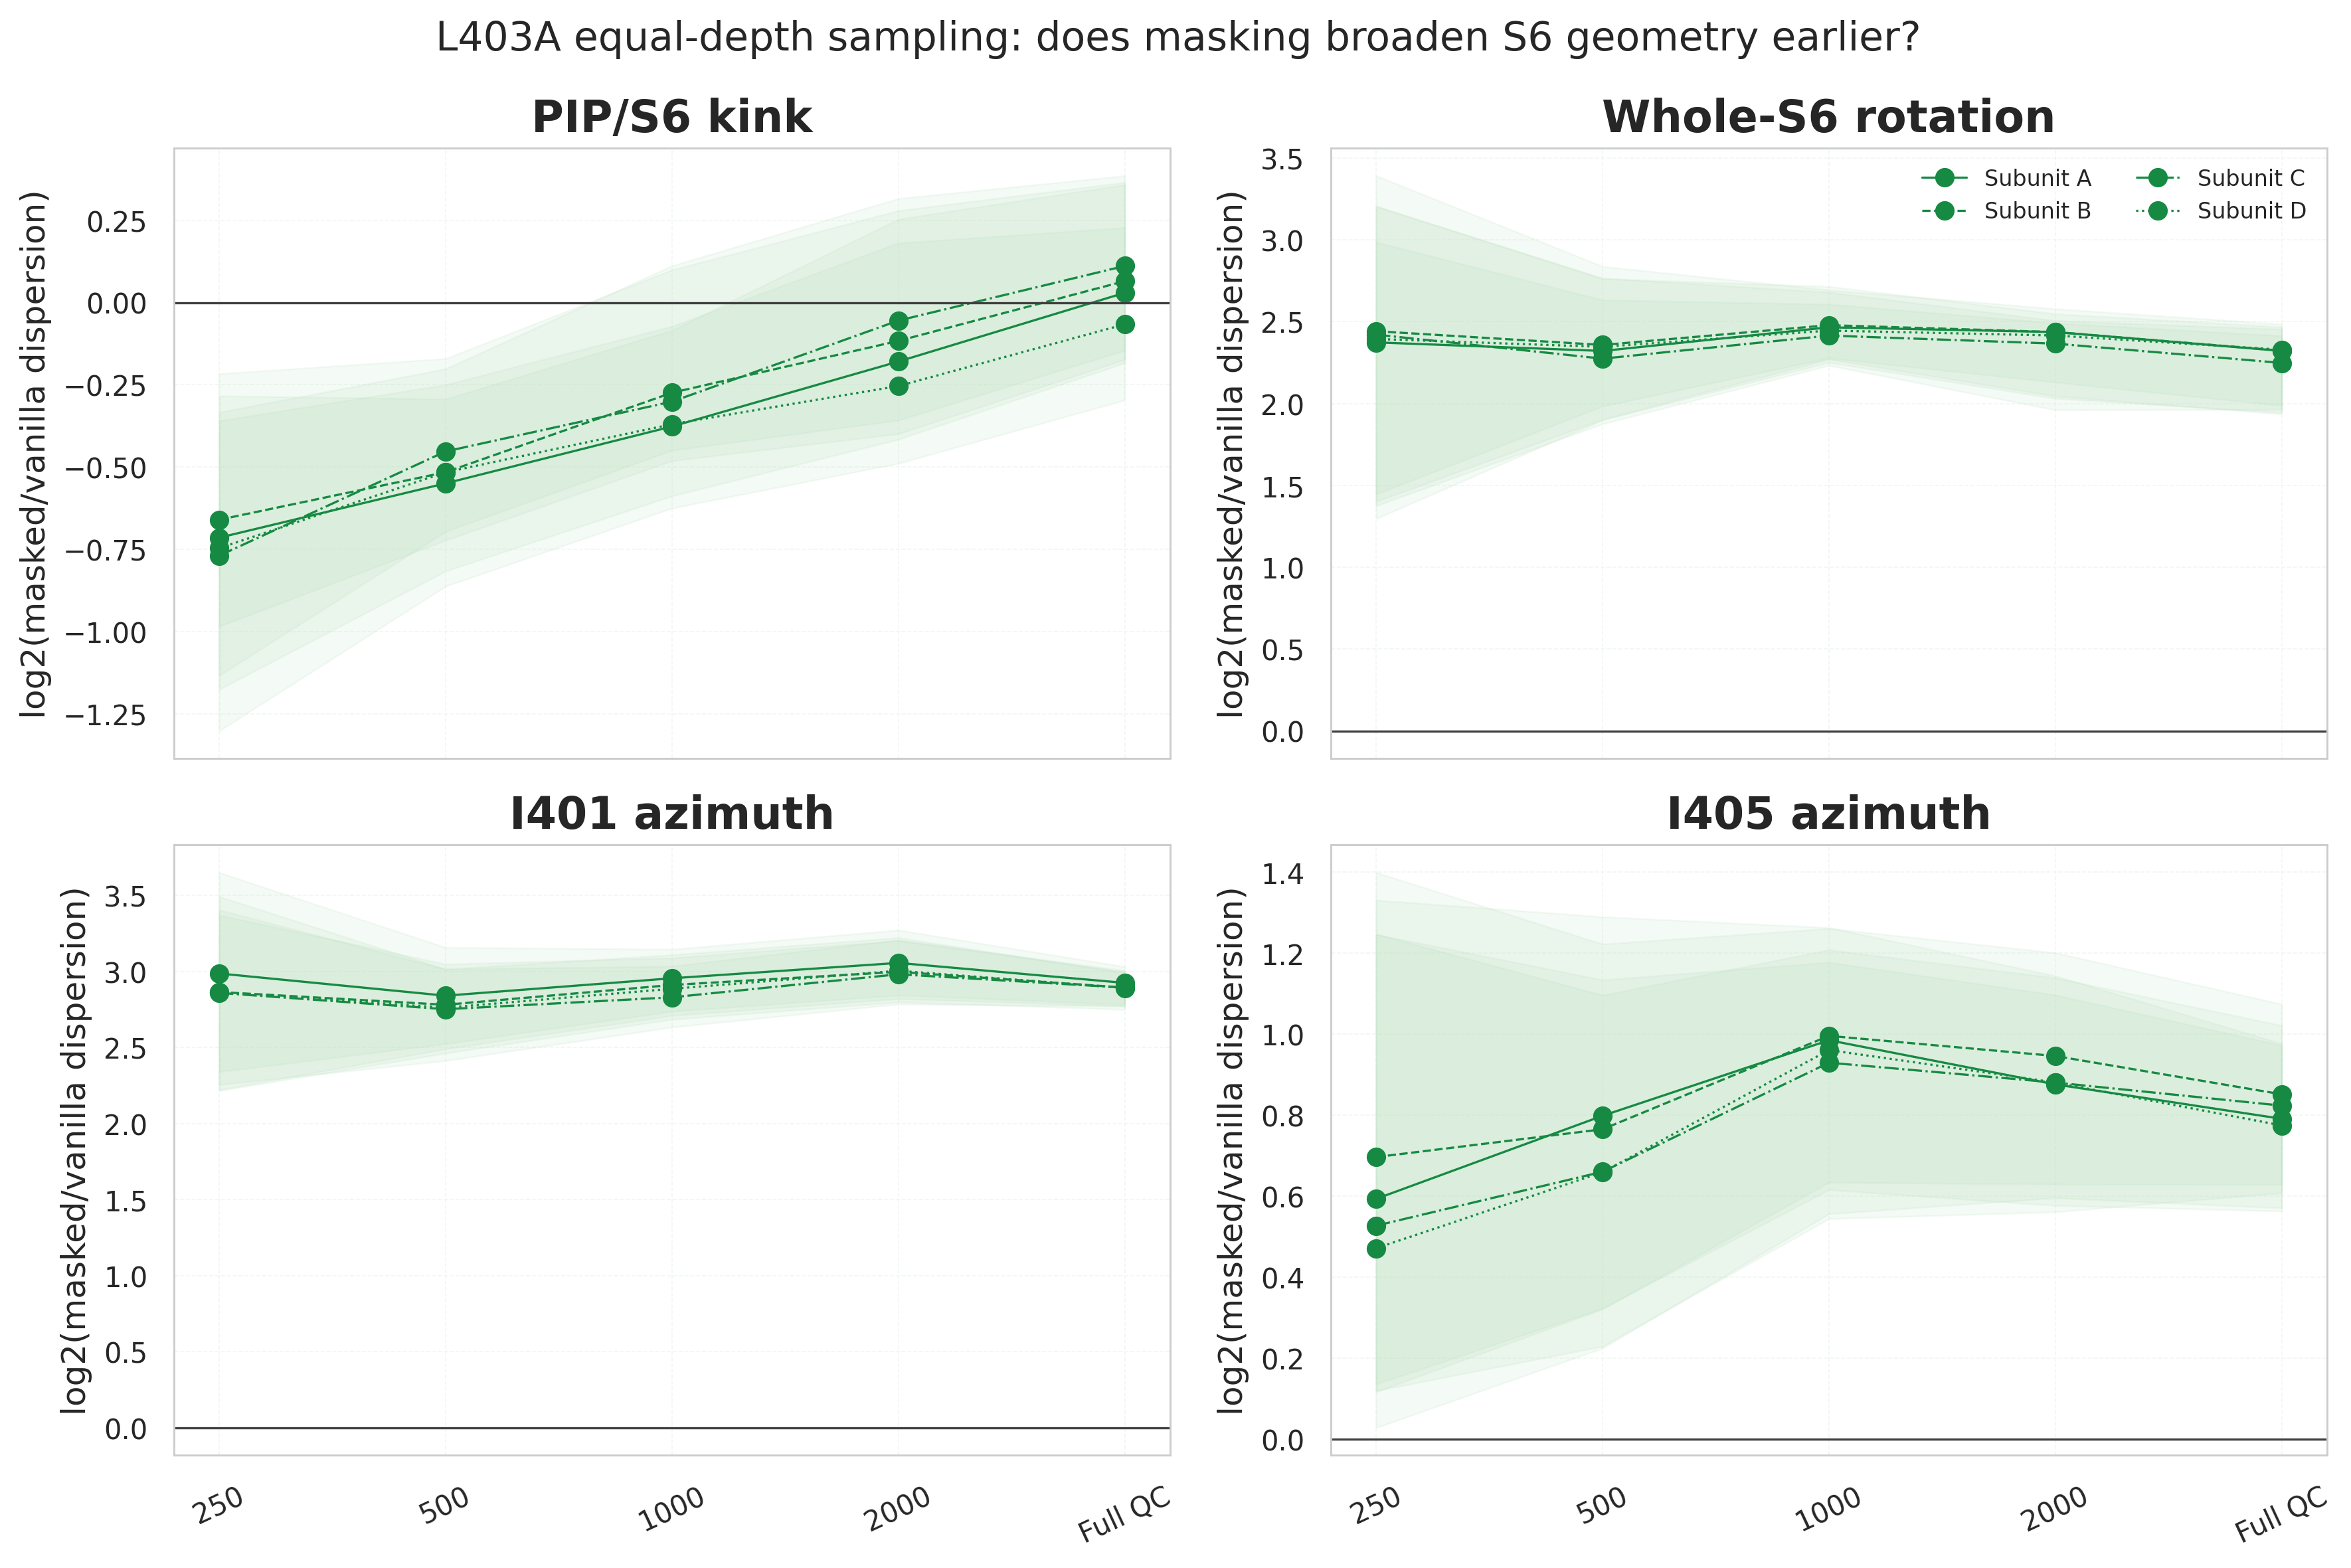

In [3]:
disp=pd.read_csv(TAB/'l403a_sampling_depth_dispersion.csv')
display(disp)
display(Image(filename=str(FIG/'l403a_sampling_depth_dispersion.png')))

## First 1,000 versus complete QC

In [4]:
display(disp[disp.depth.astype(str).isin(['1000','Full QC'])][['depth','canonical_subunit','metric','vanilla_dispersion','masked_dispersion','masked_vanilla_ratio','log2_ratio_ci_low','log2_ratio_ci_high','bootstrap_p_two_sided','bootstrap_q_within_depth','vanilla_seeds','masked_seeds']])

,depth,canonical_subunit,metric,vanilla_dispersion,masked_dispersion,masked_vanilla_ratio,log2_ratio_ci_low,log2_ratio_ci_high,bootstrap_p_two_sided,bootstrap_q_within_depth,vanilla_seeds,masked_seeds
32,1000,A,kink_angle_deg,1.649026,1.270183,0.770262,-0.587637,-0.084533,0.025974,0.029685,23,27
33,1000,A,whole_s6_rotation_vs_8SD3_deg,0.554173,3.061798,5.524987,2.251148,2.715616,0.001998,0.002664,23,27
34,1000,A,I401_azimuth_deg,0.788850,6.114740,7.751464,2.737171,3.145229,0.001998,0.002664,23,27
35,1000,A,I405_azimuth_deg,1.441081,2.852266,1.979254,0.615644,1.263099,0.001998,0.002664,23,27
36,1000,B,kink_angle_deg,1.596306,1.320101,0.826973,-0.480866,0.099012,0.139860,0.149184,23,27
37,1000,B,whole_s6_rotation_vs_8SD3_deg,0.551269,3.073660,5.575613,2.277562,2.694074,0.001998,0.002664,23,27
38,1000,B,I401_azimuth_deg,0.814745,6.125870,7.518755,2.708903,3.108861,0.001998,0.002664,23,27
39,1000,B,I405_azimuth_deg,1.404191,2.800148,1.994137,0.633775,1.261005,0.001998,0.002664,23,27
40,1000,C,kink_angle_deg,1.515507,1.229945,0.811573,-0.449148,0.111620,0.225774,0.225774,23,27
41,1000,C,whole_s6_rotation_vs_8SD3_deg,0.562494,3.000897,5.334983,2.233187,2.606949,0.001998,0.002664,23,27


## Cumulative access to 8SDA-like B/D S6 geometry

,depth,vanilla_hit_fraction,masked_hit_fraction,hit_fraction_difference,difference_ci_low,difference_ci_high,vanilla_best_score,masked_best_score,vanilla_hits,masked_hits,vanilla_seeds,masked_seeds
0,250,0.068000,0.004000,-0.06400,-0.174793,0.003681,0.055566,0.140662,17,1,6,8
1,500,0.068000,0.002000,-0.06600,-0.125019,-0.021595,0.025817,0.140662,34,1,12,14
2,1000,0.084000,0.002000,-0.08200,-0.124043,-0.046213,0.012542,0.081508,84,2,23,27
3,2000,0.075000,0.001500,-0.07350,-0.099471,-0.049960,0.010577,0.040169,150,3,46,55
4,Full QC,0.089712,0.001662,-0.08805,-0.106344,-0.069993,0.005319,0.040169,395,6,100,100


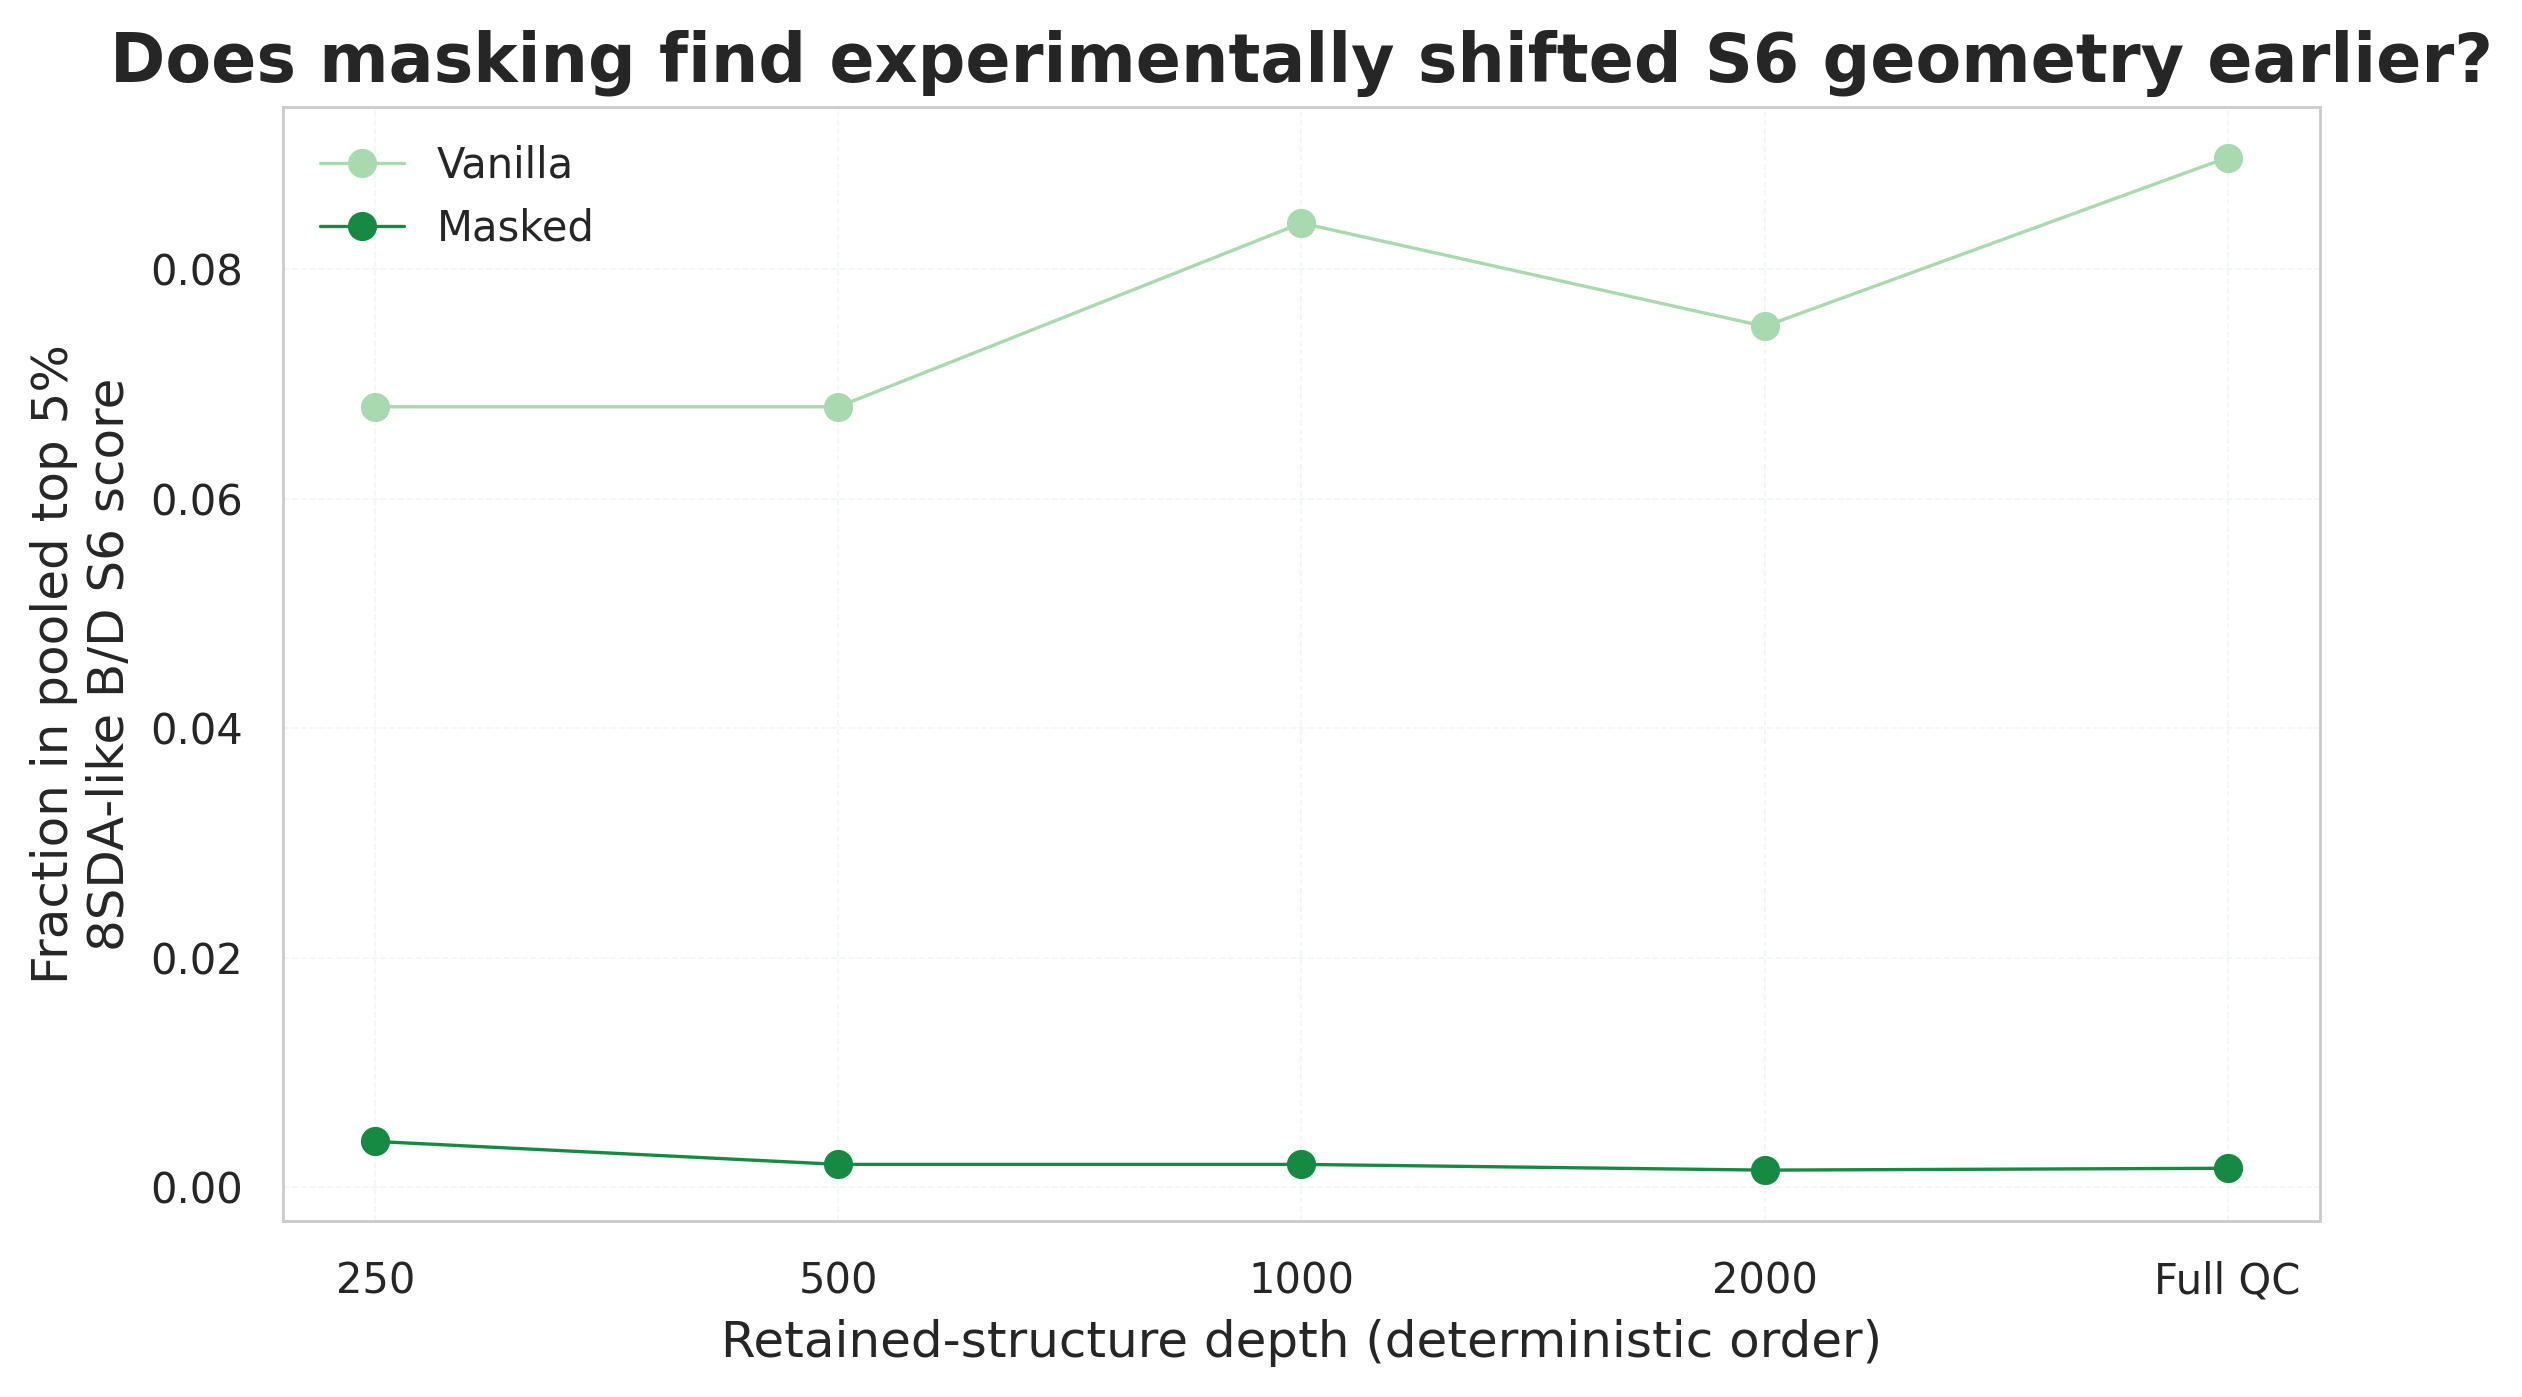

In [5]:
enrich=pd.read_csv(TAB/'l403a_sampling_depth_experimental_like_enrichment.csv')
display(enrich)
display(Image(filename=str(FIG/'l403a_sampling_depth_experimental_like_enrichment.png')))

## Statistical reading guide

- A dispersion-ratio confidence interval entirely above zero supports broader masked sampling for that specific metric and subunit.
- A hit-fraction-difference interval entirely above zero supports enrichment of 8SDA-like states under masking at that depth.
- A lower best score means the protocol has reached a more extreme 8SDA-like individual structure, which is different from increasing the population frequency of such structures.
- The first-1,000 comparison is valuable only alongside the cumulative curve and full-QC result; by itself it cannot distinguish a stable sampling effect from an arbitrary ordering fluctuation.